<a href="https://colab.research.google.com/github/nilaynishant/acrs/blob/main/04_median_composite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Overview

We will create a median composite image for a Delhi district using XArray and Dask, querying cloud-hosted Sentinel-2 data via STAC.

We use the Delhi district boundary from the uploaded `Data/delhi_1997-2012_district.json` file as our Area of Interest, then clip and save the output as a Cloud-Optimized GeoTIFF (COG).

### Setup

Determine our runtime environment.


In [ ]:
import os

if 'COLAB_RELEASE_TAG' in os.environ:
    environment = 'colab'
    if os.environ.get('VERTEX_PRODUCT') == 'COLAB_ENTERPRISE':
        environment = 'colab_enterprise'
else:
    environment = 'local'

data_folder = 'data'
output_folder = 'output'

os.makedirs(data_folder, exist_ok=True)
os.makedirs(output_folder, exist_ok=True)

print(f'Environment: {environment}')
print(f'Data folder: {data_folder}')
print(f'Output folder: {output_folder}')

If we are on Google Colab, install the required packages. Local runtimes are expected to have the packages already installed.

In [ ]:
%%capture
if environment in ['colab', 'colab_enterprise']:
  !pip install pystac-client odc-stac rioxarray dask['distributed'] botocore \
      jupyter-server-proxy

Import all required libraries. Make sure to import everything at the beginning as certain Xarray extensions are activated on import and registers certain accesors, like `.rio` and `.odc` for Xarray objects.

In [ ]:
import dask
import matplotlib.pyplot as plt
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import pystac_client
import rioxarray as rxr
import xarray as xr
from odc.stac import configure_s3_access, load


Setup a local Dask cluster. This distributes the computation across multiple workers on your computer.

In [ ]:
from dask.distributed import Client
client = Client()  # set up local cluster on the machine
client

INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:40865
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:45891'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:38691'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:35897 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:35897
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:47514
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:38769 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:38769
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:47518
INFO:distributed.scheduler:Receive client connection: Client-e6fc6168-c9a2-11f1-8f7a-0242ac1c000c
INFO:distributed.core:Starting establish

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 2
Total threads: 2,Total memory: 12.67 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40865,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35897,Total threads: 1
Dashboard: http://127.0.0.1:43961/status,Memory: 6.34 GiB
Nanny: tcp://127.0.0.1:45891,


If you are running this notebook in Colab, you will need to create and use a proxy URL to see the dashboard running on the local server.

In [ ]:
if environment == 'colab':
    from google.colab import output
    port_to_expose = 8787  # This is the default port for Dask dashboard
    print(output.eval_js(f'google.colab.kernel.proxyPort({port_to_expose})'))

https://8787-m-s-kkb-euw4b0-3vxkcmnetrebf-b.europe-west4-0.prod.colab.dev


### Load Area of Interest

Load the Delhi district boundary from the uploaded data file.

In [ ]:
# Use local path when running from the repo, GitHub raw URL as fallback (Colab)
delhi_filepath = os.path.join('Data', 'delhi_1997-2012_district.json')

if not os.path.exists(delhi_filepath):
    delhi_filepath = (
        'https://raw.githubusercontent.com/nilaynishant/acrs/main'
        '/Data/delhi_1997-2012_district.json'
    )

Read the GeoJSON and select a district. Available districts: `Central`, `East`, `North East`, `North`, `North West`, `New Delhi`, `South`, `South West`, `West`.

In [ ]:
gdf = gpd.read_file(delhi_filepath)

# Select a single district — change this to explore other parts of Delhi
district = 'New Delhi'
aoi_gdf = gdf[gdf['DISTRICT'] == district].reset_index(drop=True)
aoi_gdf

Extract the geometry.

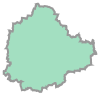

In [ ]:
geometry = aoi_gdf.geometry.union_all()
geometry

### Search and Load Sentinel-2 Imagery

Search for Sentinel-2 imagery over the selected Delhi district. We use November–December to minimize monsoon cloud cover over Delhi and filter for scenes with less than 30% cloud cover.

In [ ]:
catalog = pystac_client.Client.open(
    'https://earth-search.aws.element84.com/v1')

configure_s3_access(
    aws_unsigned=True,
)

year = 2023
start_month = 11  # Nov–Dec avoids monsoon cloud cover over Delhi
end_month = 12
time_range = f'{year}-{start_month:02d}/{year}-{end_month:02d}'

filters = {
    'eo:cloud_cover': {'lt': 30},
}

search = catalog.search(
    collections=['sentinel-2-c1-l2a'],
    intersects=geometry,
    datetime=time_range,
    query=filters,
)
items = search.item_collection()
len(items)

Visualize the resulting image footprints. You can see that our AOI covers only a small part of a single scene. When we process the data for our AOI - we will only stream the required pixels to create the composite instead of downloading entire scenes.

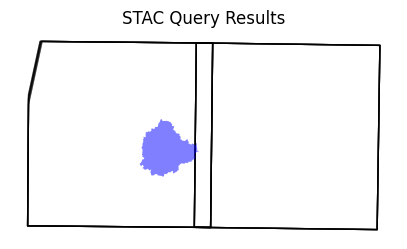

In [ ]:
items_gdf = gpd.GeoDataFrame.from_features(items.to_dict(), crs='EPSG:4326')

fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5,5)
items_gdf.plot(
    ax=ax,
    facecolor='none',
    edgecolor='black',
    alpha=0.5)

aoi_gdf.plot(
    ax=ax,
    facecolor='blue',
    alpha=0.5
)
ax.set_axis_off()
ax.set_title('STAC Query Results')
plt.show()

Load the matching images as a XArray Dataset.

In [ ]:
ds = load(
    items,
    bands=['red', 'green', 'blue', 'nir'],
    resolution=10,
    bbox=geometry.bounds,
    crs='utm',
    chunks={'x': 1024, 'y': 1024},  # Explicitly define chunk sizes
    groupby='solar_day',
)
ds

<xarray.Dataset> Size: 787MB
Dimensions:      (y: 3459, x: 3555, time: 8)
Coordinates:
  * y            (y) float64 28kB 1.455e+06 1.455e+06 ... 1.42e+06 1.42e+06
  * x            (x) float64 28kB 7.667e+05 7.667e+05 ... 8.022e+05 8.022e+05
  * time         (time) datetime64[ns] 64B 2023-04-03T05:25:16.155000 ... 202...
    spatial_ref  int32 4B 32643
Data variables:
    red          (time, y, x) uint16 197MB dask.array<chunksize=(1, 1024, 1024), meta=np.ndarray>
    green        (time, y, x) uint16 197MB dask.array<chunksize=(1, 1024, 1024), meta=np.ndarray>
    blue         (time, y, x) uint16 197MB dask.array<chunksize=(1, 1024, 1024), meta=np.ndarray>
    nir          (time, y, x) uint16 197MB dask.array<chunksize=(1, 1024, 1024), meta=np.ndarray>

The Sentinel-2 scenes come with NoData value of 0. So we set the correct NoData value before further processing.

In [ ]:
# Mask nodata values
ds = ds.where(ds != 0)

Apply scale and offset to all spectral bands

In [ ]:
scale = 0.0001
offset = -0.1
ds = ds*scale + offset

### Create a Median Composite
A very-powerful feature of XArray is the ability to easily aggregate data across dimensions - making it ideal for many remote sensing analysis. Let’s create a median composite from all the individual images.

We apply the `.median()` aggregation across the time dimension.

In [ ]:
median_composite = ds.median(dim='time')
median_composite

<xarray.Dataset> Size: 197MB
Dimensions:      (y: 3459, x: 3555)
Coordinates:
  * y            (y) float64 28kB 1.455e+06 1.455e+06 ... 1.42e+06 1.42e+06
  * x            (x) float64 28kB 7.667e+05 7.667e+05 ... 8.022e+05 8.022e+05
    spatial_ref  int32 4B 32643
Data variables:
    red          (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    green        (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    blue         (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    nir          (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>

Select the required bands.

In [ ]:
rgb_composite = median_composite[['red', 'green', 'blue']]
rgb_composite

<xarray.Dataset> Size: 148MB
Dimensions:      (y: 3459, x: 3555)
Coordinates:
  * y            (y) float64 28kB 1.455e+06 1.455e+06 ... 1.42e+06 1.42e+06
  * x            (x) float64 28kB 7.667e+05 7.667e+05 ... 8.022e+05 8.022e+05
    spatial_ref  int32 4B 32643
Data variables:
    red          (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    green        (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    blue         (y, x) float32 49MB dask.array<chunksize=(2048, 2048), meta=np.ndarray>

So far all the operations that we have created a computation graph. To run this computation using the local Dask cluster, we must call `.compute()`.

In [ ]:
%%time
rgb_composite = rgb_composite.compute()

CPU times: user 8.1 s, sys: 1.21 s, total: 9.31 s
Wall time: 2min 20s


Alternatively, if you do not have access to the Dask dashboard, or want a simple progress-bar to track the computation you can use the Dask progress bar. Replace the cell above with the following code. Monitoring the computation with the progress bar requires us to start the computation using `.persist()` and later load the result into memory using `.compute()`. We use `notebook=False` for a simple progress bar widget compatible with Colab.

```
from dask.distributed import progress
rgb_composite = rgb_composite.persist()
progress(rgb_composite, notebook=False)
rgb_composite = rgb_composite.compute()
```

### Visualize the Results

The composite is creating from all the pixels within the bounding box of the geometry. We can use `rioxarray` to clip the image to the city boundary to remove pixels outside the polygon.

To visualize our Dataset, we first convert it to a DataArray using the `to_array()` method. All the variables will be converted to a new dimension. Since our variables are image bands, we give the name of the new dimesion as band.


In [ ]:
rgb_composite_da = rgb_composite.to_array('band')
rgb_composite_da

<xarray.DataArray (band: 3, y: 3459, x: 3555)> Size: 148MB
array([[[0.1286    , 0.1668    , 0.15495   , ..., 0.22675   ,
         0.22469999, 0.2246    ],
        [0.13849999, 0.13164999, 0.14225   , ..., 0.2296    ,
         0.22635001, 0.22749999],
        [0.106     , 0.08915   , 0.132     , ..., 0.2142    ,
         0.22340001, 0.22449999],
        ...,
        [0.13105   , 0.0713    , 0.05954999, ..., 0.14275   ,
         0.12969999, 0.12189999],
        [0.14365   , 0.08755   , 0.07394999, ..., 0.15505   ,
         0.14185   , 0.13479999],
        [0.15275   , 0.11679999, 0.10389999, ..., 0.19209999,
         0.17699999, 0.16205001]],

       [[0.09769999, 0.11489999, 0.10959999, ..., 0.1574    ,
         0.15630001, 0.153     ],
        [0.10254999, 0.09859999, 0.10155   , ..., 0.1557    ,
         0.1544    , 0.15079999],
        [0.08339999, 0.07389999, 0.0948    , ..., 0.14519998,
         0.1519    , 0.1516    ],
...
        [0.1015    , 0.07094999, 0.0695    , ..., 0.105     ,
         0.10065   , 0.09959999],
        [0.10689999, 0.0799    , 0.07169999, ..., 0.10519999,
         0.09949999, 0.09989999],
        [0.10399999, 0.09189999, 0.08094999, ..., 0.10999999,
         0.10389999, 0.10199999]],

       [[0.05895   , 0.07439999, 0.07159999, ..., 0.1151    ,
         0.11219999, 0.10969999],
        [0.0654    , 0.0623    , 0.06315   , ..., 0.11399999,
         0.11179999, 0.1089    ],
        [0.05064999, 0.0417    , 0.0607    , ..., 0.1001    ,
         0.10609999, 0.1064    ],
        ...,
        [0.06265   , 0.0399    , 0.03945   , ..., 0.07415   ,
         0.07365   , 0.0722    ],
        [0.0654    , 0.04645   , 0.04499999, ..., 0.07049999,
         0.06954999, 0.07069999],
        [0.06424999, 0.05679999, 0.0515    , ..., 0.0719    ,
         0.06909999, 0.06885   ]]], dtype=float32)
Coordinates:
  * band         (band) object 24B 'red' 'green' 'blue'
  * y            (y) float64 28kB 1.455e+06 1.455e+06 ... 1.42e+06 1.42e+06
  * x            (x) float64 28kB 7.667e+05 7.667e+05 ... 8.022e+05 8.022e+05
    spatial_ref  int32 4B 32643

In [ ]:
image_crs = rgb_composite_da.rio.crs
aoi_gdf_reprojected = aoi_gdf.to_crs(image_crs)
rgb_composite_clipped = rgb_composite_da.rio.clip(aoi_gdf_reprojected.geometry)
rgb_composite_clipped

<xarray.DataArray (band: 3, y: 3421, x: 3513)> Size: 144MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], dtype=float32)
Coordinates:
  * band         (band) object 24B 'red' 'green' 'blue'
  * y            (y) float64 27kB 1.454e+06 1.454e+06 ... 1.42e+06 1.42e+06
  * x            (x) float64 28kB 7.669e+05 7.669e+05 ... 8.02e+05 8.021e+05
    spatial_ref  int64 8B 0

For visualizing, we resample it to a lower resolution preview

In [ ]:
preview = rgb_composite_clipped.rio.reproject(
    rgb_composite_clipped.rio.crs, resolution=100
)

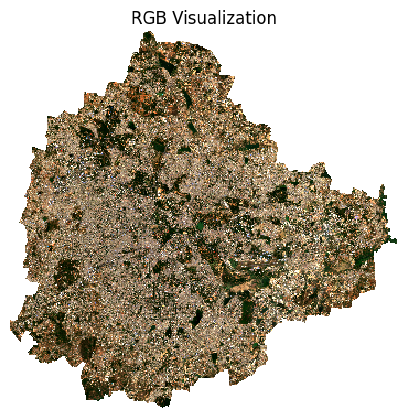

In [ ]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5,5)
preview.sel(band=['red', 'green', 'blue']).plot.imshow(
    ax=ax,
    robust=True)
ax.set_title('RGB Visualization')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

We can manually apply a contrast stretch as well.

In [ ]:
percentile_stretch = (1, 95)
stretch_vmin, stretch_vmax = np.nanpercentile(preview.values, percentile_stretch)
print(stretch_vmin, stretch_vmax)

0.030799992382526398 0.22739998996257782


In [ ]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5,5)
preview.sel(band=['red', 'green', 'blue']).plot.imshow(
    ax=ax,
    vmin=stretch_vmin,
    vmax=stretch_vmax)
ax.set_title(f'Delhi – {district} District\nSentinel-2 Composite {year}')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

### Export the Composite

We use the `rio` accessor to save the results as a Cloud-Optimized GeoTIFF.

In [ ]:
output_file = f'raw_composite_{year}.tif'
output_path = os.path.join(output_folder, output_file)
rgb_composite_clipped.rio.to_raster(output_path, driver='COG')
print(f'Wrote {output_path}')

The raw composite is suitable for downstream scientific analysis as it preserves the pixel reflectance values.Sometimes it is desirable to export the output as a colorized RGBA image. This visualized output suitable for use user-facing applications like basemaps or prints.

The `odc-geo` package provides a handy [`to_rgba()`](https://odc-geo.readthedocs.io/en/latest/_api/odc.geo.xr.to_rgba.html) function to save the visualized version of the composite. This function can be used via the `.odc` accessor.

In [ ]:
# Convert to a Xarray Dataset first
rgb_composite_ds = rgb_composite_clipped.to_dataset(dim='band')
composite_rgba = rgb_composite_ds.odc.to_rgba(
    vmin=stretch_vmin, vmax=stretch_vmax)


Save the visualized output.

In [ ]:
visualized_file = f'visualized_composite_{year}.tif'
visualized_output_path = os.path.join(output_folder, visualized_file)
composite_rgba.odc.write_cog(visualized_output_path, overwrite=True)
print(f'Wrote {visualized_output_path}')

Close the dask client. This presents multiple clients being instantiated when running different notebooks on the same machine. This is not required on Colab but a good practice when you are running it on a local machine. Uncomment and run to shutdown the dask cluster.

In [ ]:
#client.shutdown()

### Exercise

Create and export median composites for two different Delhi districts (e.g., `'Central'` and `'South'`) for the year 2023. Compare how urban land cover differs between the districts.